# PA 766 Module 10 Supervised ML 2 Regression
## Implementing and interpreting regression models

* Target Variable: Solar roof-area coverage
* Predictors: Demographic and built environmental varaibles

### 0. Setup

Dataset: `solardep-bg-co.csv`

In [30]:
# Install these packages only if needed
# %pip install -q numpy==1.26.4 scipy==1.15.3 pandas==2.2.3 scikit-learn==1.6.1 xgboost==3.0.5 shap==0.49.1 matplotlib==3.10.6

In [ ]:
import numpy as np  # Work with arrays and numerical calculations
import pandas as pd  # Read and organize tabular data
import matplotlib.pyplot as plt  # Create plots
import xgboost as xgb  # Fit boosted regression trees
import shap  # Explain model predictions
from IPython.display import display  # Display tables in the notebook
from sklearn.dummy import DummyRegressor  # Create a simple prediction baseline
from sklearn.linear_model import LinearRegression  # Fit a linear regression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score  # Measure prediction error and fit
from sklearn.model_selection import train_test_split  # Separate training and held-out data
from sklearn.tree import DecisionTreeRegressor, plot_tree  # Fit and draw a regression tree

SEED = 1982  # Choose a seed for repeatable splits and sampling
plt.rcParams.update({  # Set shared plot formatting
    'figure.dpi': 115,  # Set image resolution
    'font.size': 11,  # Set the default text size
    'axes.spines.top': False,  # Hide the top border
    'axes.spines.right': False,  # Hide the right border
})

In [ ]:
from google.colab import drive  # Connect Colab to Google Drive
drive.mount('/content/drive')  # Make Drive files accessible to this notebook

Mounted at /content/drive


### 1. Define the outcome and inspect the data

Each row represents a census block group. We preserve the source row index and block-group ID for tracing predictions, but never use IDs as model features.

$$
y = \texttt{pvcountperhouse2020}
  = \frac{\texttt{count\_pv\_n}}{\texttt{house}}.
$$

We retain the original outcome scale: **PV counts per household**. For example, 0.08 counts per household is equivalent to 8 counts per 100 households, but the code does not multiply the target by 100. This is a count-to-household ratio, not the percentage of households adopting solar, a probability, or the roof-area outcome in the slides. RMSE, MAE, predictions, and SHAP values all use PV counts per household.

This is a retrospective teaching exercise. The CSV combines measures with different or unspecified dates; check the original documentation and what would have been known at prediction time before treating it as a deployable forecast.

In [ ]:
raw = pd.read_csv(  # Load the neighborhood dataset
    '/content/drive/MyDrive/a-ncsu-courses/PA766-2026/Data/Rooftop Solar Deployment/solardep-bg-co.csv',  # Locate the CSV in Drive
    dtype={'id_bg': 'string', 'id_tract': 'string'},  # Read geographic IDs as text
)
print(f'{len(raw):,} neighborhoods; {raw.shape[1]} columns in the source file.')  # Show the dataset size
display(  # Preview the first five neighborhoods
    raw[['id_bg', 'NAME10', 'house', 'count_pv_n', 'pvcountperhouse2020']].head()  # Show IDs and outcome fields
)

3,441 neighborhoods; 140 columns in the source file.


,id_bg,NAME10,house,count_pv_n,pvcountperhouse2020
0,80010078011,Aurora,618,0,0.000000
1,80010078012,Aurora,725,0,0.000000
2,80010078021,Aurora,542,3,0.005535
3,80010078022,Aurora,394,6,0.015228
4,80010078023,Aurora,518,6,0.011583


### 2. Select predictors and account for missing information

We retain the 43 predictors in the original example, including neighborhood, utility, policy, and risk measures. We exclude IDs, the outcome itself, PV counts used to construct it, and other solar-outcome columns. Including a component of the outcome would give the model an artificial shortcut.

The following labels are reading aids based on the original notebook, not a replacement for a source codebook. Values labeled **share** remain stored fractions; `EP_*` variables retain their stored percentage scale. Risk scores and rurality retain their supplied numeric encodings. Confirm definitions, denominators, category meanings, and dates before substantive research. A tree threshold on a coded variable may need special interpretation.

In [ ]:
# Map dataset columns to readable plot labels.
FEATURE_LABELS = {
    # Environment, population, and housing
    'prop_treearea': 'Tree / land area (share)',
    'dniavg': 'Solar radiation',
    'mh_income_2019': 'Median household income',
    'medianage': 'Median Age',
    'prop_age65over': 'Age 65+ (share)',
    'prop_belowpov': 'Below poverty (share)',
    'prop_bachelorhigher': 'BA+ measure (share)',
    'prop_renteroccupied': 'Renters (share)',
    'YearStructureBuilt': 'Year Structure Built',
    'avg_bdrooms': 'Avg. No. Bedrooms',
    'MedianHomeValue': 'Median Home Value',
    'ruca_primary': 'Rurality',
    'dem_votes': 'Democratic vote (share)',
    'black_prop': 'Black population (share)',
    'his_prop': 'Hispanic population (share)',
    'asian_prop': 'Asian population (share)',
    'others_prop': 'Other race (share)',
    # Electricity infrastructure and utility characteristics
    'ln_TransLineVolt': 'Log transmission voltage',
    'ln_TransLineLength': 'Log transmission length',
    'utiltypemuni': 'Muni. Utilities',
    'utiltypecoop': 'Rural Co-Ops',
    'res_rate': 'Resident. Elec. Rate',
    'comm_rate': 'Commercial Elec. Rate',
    # Solar policies and permitting
    'solarmandate': 'Solar Mandate',
    'nem': 'Net Metering',
    'solsmart_awardee': 'SolSmart Awardee',
    'online_permitting': 'Online Permitting',
    'sameday_inperson_permitting': 'Sameday Inperson Permit',
    'permitandpreinstalldays': 'Permit & Pre-Install Days',
    # Hazard scores
    'DRGT_EALS': 'Drought score',
    'WFIR_EALS': 'Wildfire score',
    'HAIL_EALS': 'Hail score',
    'WNTW_EALS': 'Winter weather score',
    'SWND_EALS': 'Strong wind score',
    'TRND_EALS': 'Tornado score',
    # Social vulnerability measures
    'EP_DISABL': '% Disability',
    'EP_SNGPNT': '% Single Parent',
    'EP_LIMENG': '% Limited English',
    'EP_MUNIT': 'Multi-unit housing (%)',
    'EP_MOBILE': '% Mobile Home',
    'EP_CROWD': 'Crowded housing (%)',
    'EP_NOVEH': '% No Vehicle',
    'EP_UNEMP': '% Unemployed'
}
FEATURES = list(FEATURE_LABELS)  # Keep predictor names in their original order

model_data = (  # Prepare the outcome and selected predictors
    raw[['pvcountperhouse2020'] + FEATURES]  # Select the modeling columns
    .replace(np.inf, np.nan)  # Treat positive infinity as a missing value
)
missing = pd.DataFrame({  # Summarize missing values before removing rows
    'missing_n': model_data.isna().sum(),  # Count missing values in each column
    'missing_pct': 100 * model_data.isna().mean(),  # Express missingness as a percentage
})
display(  # Show columns that contain missing values
    missing.loc[missing.missing_n > 0]  # Keep columns with at least one missing value
    .sort_values('missing_n', ascending=False).round(1)  # List the most incomplete columns first
)
complete_data = model_data.dropna()  # Remove rows missing any selected value
y = complete_data['pvcountperhouse2020'].rename('PV counts per household')  # Define the prediction target
X = complete_data[FEATURES].copy()  # Separate the predictor columns
print(  # Report how many neighborhoods remain
    f'Complete cases: {len(X):,} of {len(raw):,} neighborhoods; '
    f'{len(raw) - len(X):,} rows removed.'
)

,missing_n,missing_pct
solsmart_awardee,1102,32.0
sameday_inperson_permitting,1102,32.0
online_permitting,1102,32.0
permitandpreinstalldays,1102,32.0
solarmandate,365,10.6


Complete cases: 2,328 of 3,441 neighborhoods; 1,113 rows removed.


**Pause:** If permitting information is systematically missing for certain municipalities, what population would a complete-case analysis describe?

### 3. Reproduce the original 90/10 split

| Set | Share | Role in this fixed example |
|---|---:|---|
| Training | 90% | Fit each model using 2,095 complete observations |
| Held-out | 10% | Evaluate predictions on the remaining 233 observations |

,rows
Training (90%),2095
Held-out (10%),233


,PV counts per household
count,2095.0000
mean,0.0787
std,0.0988
min,0.0000
50%,0.0461
90%,0.2008
99%,0.4465
max,0.7835


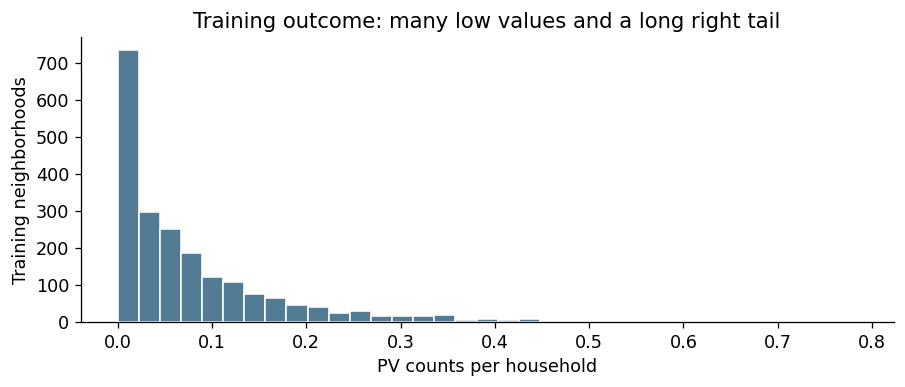

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(  # Split predictors and outcomes together
    X, y,  # Supply the predictors and target
    train_size=0.9,  # Use 90% of observations for training
    test_size=0.1,  # Hold out 10% for evaluation
    random_state=SEED,  # Reproduce the same split
)

display(pd.DataFrame(  # Show the number of rows in each set
    {'rows': [len(X_train), len(X_test)]},  # Count training and held-out observations
    index=['Training (90%)', 'Held-out (10%)'],  # Label the two sets
))

display(y_train.describe(percentiles=[0.5, 0.9, 0.99]).round(4).to_frame())  # Summarize training outcomes
fig, ax = plt.subplots(figsize=(8, 3.5))  # Create the histogram area
ax.hist(y_train, bins=35, color='#527b94', edgecolor='white')  # Group outcomes into 35 bins
ax.set(  # Label the histogram
    xlabel='PV counts per household',  # Identify the outcome units
    ylabel='Training neighborhoods',  # Identify what each bin counts
    title='Training outcome: many low values and a long right tail',  # Describe the distribution
)
plt.tight_layout()  # Fit labels within the figure
plt.show()  # Display the histogram

The complete-case rows go directly into the models. There is no imputation, target rescaling, or additional split in the main example. The benchmark comparison uses the three models fitted in Section 4. XGBoost is introduced separately in Section 5. Small numerical differences can still arise across XGBoost versions or execution platforms.

### 4. Fit models whose predictions we can benchmark

The mean baseline ignores all features. Linear regression connects to familiar regression analysis. A tree of depth two gives a readable sequence of splits: each leaf predicts the mean training outcome among observations in that leaf.

We compare **predictive** performance here; we are not using linear-regression coefficients as causal estimates or running hypothesis tests.

$$
\mathrm{MAE}=\frac{1}{n}\sum_i |y_i-\hat y_i|,
\qquad
\mathrm{RMSE}=\sqrt{\frac{1}{n}\sum_i (y_i-\hat y_i)^2}.
$$
Lower MAE and RMSE are better. RMSE penalizes large errors more heavily. Both have units of PV counts per household. Higher test-set $R^2$ is better; it can be negative if predictions are worse than using the evaluation set's mean. The deployed mean baseline below uses the **training** mean, so its evaluation $R^2$ need not be exactly zero.

In [15]:
def regression_metrics(actual, predicted):  # Calculate the same metrics for every model
    return {  # Return a named set of scores
        'RMSE': np.sqrt(mean_squared_error(actual, predicted)),  # Measure error with extra weight on large misses
        'MAE': mean_absolute_error(actual, predicted),  # Calculate the average absolute error
        'R2': r2_score(actual, predicted),  # Compare fit with predicting the outcome mean
    }

models = {  # Store the benchmark models by name
    'Training mean': DummyRegressor(strategy='mean'),  # Predict the training mean for every neighborhood
    'Linear regression': LinearRegression(),  # Fit a linear combination of predictors
    'Small regression tree': DecisionTreeRegressor(  # Fit a tree that is easy to visualize
        max_depth=2,  # Allow at most two splits along a path
        min_samples_leaf=25,  # Require at least 25 training rows per leaf
        random_state=SEED,  # Make the tree fit reproducible
    ),
}
for estimator in models.values():  # Go through each benchmark model
    estimator.fit(X_train, y_train)  # Learn from the training predictors and outcomes

benchmark_models = models.copy()  # Keep these three models for the benchmark plot

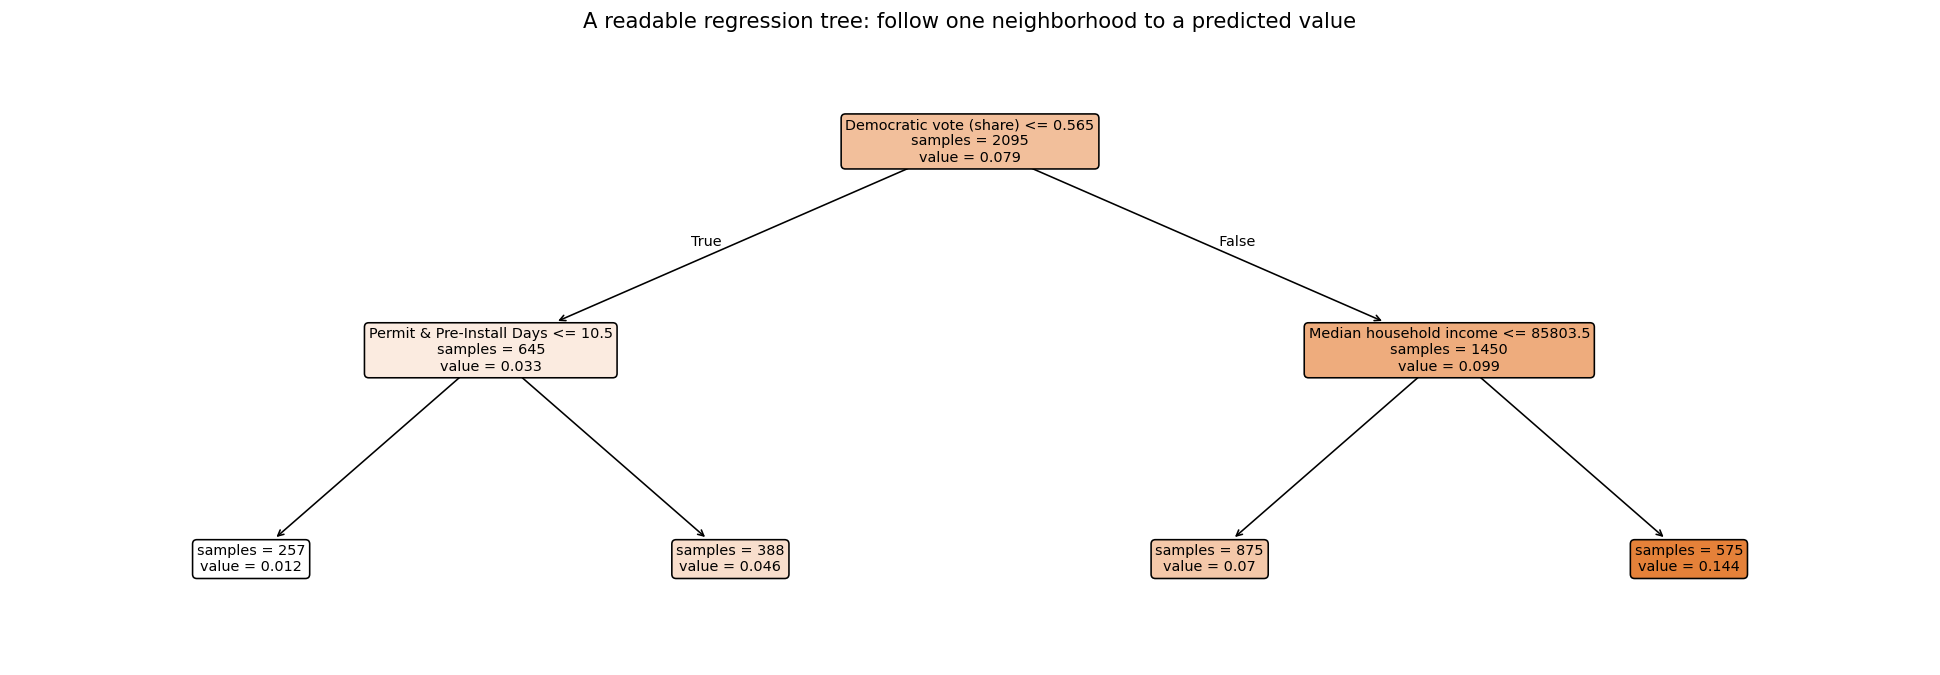

In [16]:
fig, ax = plt.subplots(figsize=(17, 6))  # Create space for the tree diagram
plot_tree(  # Draw the fitted tree's splits and predictions
    models['Small regression tree'],  # Use the small benchmark tree
    feature_names=[FEATURE_LABELS[f] for f in FEATURES],  # Replace column names with readable labels
    filled=True,  # Color nodes by their predicted value
    rounded=True,  # Round the node boxes
    impurity=False,  # Hide the impurity statistic
    precision=3,  # Display numbers to three decimal places
    fontsize=9,  # Set the node text size
    ax=ax,  # Draw on the chosen plotting area
)
ax.set_title('A readable regression tree: follow one neighborhood to a predicted value')  # Add a title
plt.tight_layout()  # Fit the diagram within the figure
plt.show()  # Display the tree

**Check your understanding:** At each split, go left if the condition is true and right otherwise. Trace a neighborhood to a leaf. What does `value` mean? Why could a shallow tree be useful even if its RMSE is worse? The displayed thresholds are rounded; the fitted model uses unrounded thresholds for exact routing.

<details><summary>Instructor discussion notes</summary>
The leaf value is a fitted prediction in PV counts per household, calculated as the average training outcome in that leaf. It is not a regression coefficient. The model can expose the basic prediction mechanism and offer a simple benchmark. Interpretability and prediction accuracy are separate criteria.
</details>

### 5. Fit XGBoost

Boosting adds trees sequentially. For squared-error regression, each new tree responds to the current prediction errors through the loss derivatives.

Example:

| Setting | Original value |
|---|---:|
| Learning rate | 0.05 |
| Maximum tree depth | 7 |
| Boosting rounds | 300, fixed |
| Row subsampling | 0.8 |
| Feature subsampling per tree | 0.5 |
| L1 penalty (`alpha`) | 5 |
| L2 penalty (`reg_lambda`) | 0 |
| Initial prediction (`base_score`) | 0.5 |


In [21]:
XGB_PARAMS = {  # Store the original model settings
    'objective': 'reg:squarederror',  # Minimize squared prediction errors
    'gamma': 0,  # Require no additional loss reduction to permit a split
    'learning_rate': 0.05,  # Shrink each new tree's contribution
    'max_depth': 7,  # Limit the depth of each tree
    'subsample': 0.8,  # Sample 80% of training rows per boosting round
    'colsample_bytree': 0.5,  # Sample half the features for each tree
    'alpha': 5,  # Apply L1 regularization to leaf weights
    'reg_lambda': 0,  # Turn off L2 regularization
    'n_estimators': 300,  # Fit 300 boosting rounds
    'scale_pos_weight': 0,  # Retain the unused legacy classification setting
    'base_score': 0.5,  # Set the initial prediction before boosting
    'random_state': 185,  # Retain the original estimator seed
    'seed': 855,  # Retain the original booster seed
}

xgb_model = xgb.XGBRegressor(  # Create the regression model
    **XGB_PARAMS,  # Pass the stored settings as keyword arguments
    verbosity=0,  # Suppress XGBoost log messages
)
xgb_model.fit(  # Learn the sequence of trees
    X_train, y_train,  # Fit using training observations only
    eval_set=[(X_train, y_train), (X_test, y_test)],  # Record error on both sets each round
    verbose=False,  # Hide the per-round error printout
)
models['XGBoost'] = xgb_model  # Add XGBoost to the comparison models

### 6. Evaluate the fixed models and diagnose errors

Report all four models on the same held-out observations for teaching comparison. XGBoost retains the original settings; the notebook does not automatically select a model family from these results. The three benchmark scores use the same held-out predictions as the earlier bar chart; this table adds XGBoost and the MAE and R2 metrics. If these results motivate changes, use a separate validation/test design for any claim about the revised model.

In [22]:
test_predictions = {  # Store held-out predictions from each model
    name: model.predict(X_test)  # Predict outcomes for the same held-out neighborhoods
    for name, model in models.items()  # Repeat for every fitted model
}
test_results = pd.DataFrame({  # Assemble a performance comparison
    name: regression_metrics(y_test, pred)  # Compare predictions with observed outcomes
    for name, pred in test_predictions.items()  # Score every model's predictions
}).T  # Put models in rows and metrics in columns
display(test_results.round(5))  # Display scores to five decimal places

pred_test = test_predictions['XGBoost']  # Keep XGBoost predictions for the next plots
improvement = 100 * (  # Express the RMSE reduction as a percentage
    1 - test_results.loc['XGBoost', 'RMSE'] / test_results.loc['Training mean', 'RMSE']  # Compare XGBoost with the mean baseline
)
print(f'RMSE reduction relative to the training-mean baseline: {improvement:.1f}%')  # Report the relative improvement

,RMSE,MAE,R2
Training mean,0.09756,0.06849,-0.00691
Linear regression,0.07683,0.05305,0.37553
Small regression tree,0.08435,0.05424,0.24736
XGBoost,0.06627,0.04565,0.53542


RMSE reduction relative to the training-mean baseline: 32.1%


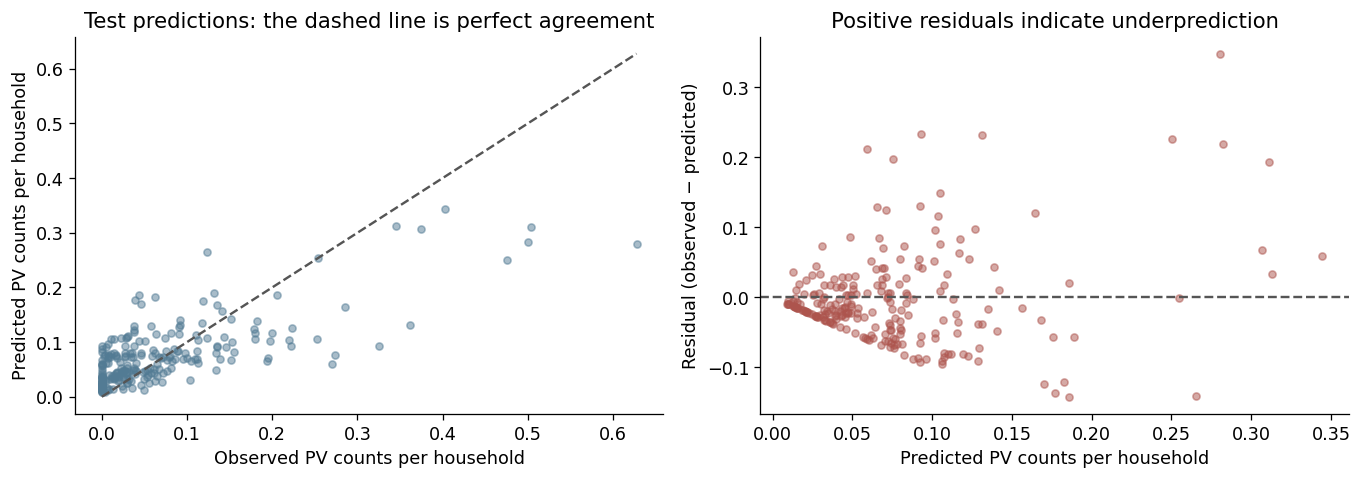

,id_bg,place,observed,predicted,absolute_error
743,80130125091,Boulder,0.6277,0.2802,0.3475
881,80130608002,Erie,0.3257,0.0932,0.2325
1247,80310041061,Aurora,0.3619,0.1310,0.2309
767,80130127053,Boulder,0.4760,0.2502,0.2258
735,80130125052,Boulder,0.5005,0.2823,0.2182


In [23]:
residuals = y_test.to_numpy() - pred_test  # Positive residuals indicate underprediction
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))  # Create two side-by-side diagnostic plots
limits = [  # Set the endpoints of the perfect-prediction line
    min(0, y_test.min(), pred_test.min()),  # Find the lower endpoint
    max(y_test.max(), pred_test.max()),  # Find the upper endpoint
]
axes[0].scatter(y_test, pred_test, alpha=0.5, s=20, color='#527b94')  # Compare observed and predicted outcomes
axes[0].plot(limits, limits, '--', color='#555555')  # Mark where predictions equal observations
axes[0].set(  # Label the prediction plot
    xlabel='Observed PV counts per household',  # Label actual outcomes
    ylabel='Predicted PV counts per household',  # Label model predictions
    title='Test predictions: the dashed line is perfect agreement',  # Explain the reference line
)
axes[1].scatter(pred_test, residuals, alpha=0.5, s=20, color='#ad544d')  # Look for patterns in prediction errors
axes[1].axhline(0, linestyle='--', color='#555555')  # Mark zero prediction error
axes[1].set(  # Label the residual plot
    xlabel='Predicted PV counts per household',  # Label the model's predicted values
    ylabel='Residual (observed − predicted)',  # Define the error direction
    title='Positive residuals indicate underprediction',  # Explain positive errors
)
plt.tight_layout()  # Keep labels from overlapping
plt.show()  # Display both diagnostic plots

prediction_table = pd.DataFrame({  # Attach predictions to neighborhood identifiers
    'id_bg': raw.loc[y_test.index, 'id_bg'],  # Retrieve matching block-group IDs
    'place': raw.loc[y_test.index, 'NAME10'],  # Retrieve matching place names
    'observed': y_test,  # Include actual outcomes
    'predicted': pred_test,  # Include XGBoost predictions

}, index=y_test.index)  # Preserve the original row identifiers
display(  # Show the five largest prediction errors
    prediction_table.assign(absolute_error=np.abs(residuals))  # Calculate error magnitudes
    .sort_values('absolute_error', ascending=False)  # Put the largest errors first
    .head(5).round(4)  # Keep five rows and round displayed values
)

**Inspect the errors and suggest the next steps** Compare XGBoost's MAE and RMSE. Which neighborhoods are poorly predicted? Does the model tend to underpredict high values? What would the error size mean for an agency using these predictions?

### 7. SHAP: explain one prediction first

Accuracy tells us how well predictions match observations. SHAP answers a different question: **how does this fitted model allocate a prediction among its input features, relative to a reference?** We interpret the original 300-round XGBoost model here; explaining it does not prove that it is the best model.

For a neighborhood $i$:
$$
\hat y_i = \underbrace{E[f(X)]}_{\text{reference prediction}} + \sum_j \underbrace{\phi_{ij}}_{\text{feature contribution}}.
$$

The reference is the model's average prediction over a background sample. A feature's SHAP value allocates part of the difference between the neighborhood's prediction and that reference, averaging marginal contributions across feature coalitions. Contributions can be positive or negative; they are not regression slopes.

We use 100 randomly selected **training** neighborhoods as the reference and explain a reproducible sample of up to 200 **test** neighborhoods. `TreeExplainer` is efficient for tree ensembles. We explicitly choose `feature_perturbation='interventional'` to make the background choice visible. Despite its technical name, this setting does **not** turn an observational predictive model into a causal model. It can evaluate combinations that are unusual when features are correlated, such as income and home value. Different backgrounds and dependence assumptions can change the attribution.

For more information: See the [TreeExplainer documentation](https://shap.readthedocs.io/en/stable/generated/shap.TreeExplainer.html).

In [24]:
background = X_train.sample(  # Select training rows to define the SHAP reference
    n=min(100, len(X_train)),  # Use up to 100 reference neighborhoods
    random_state=SEED,  # Reproduce the same background sample
)
X_explain = X_test.sample(  # Select held-out neighborhoods to explain
    n=min(200, len(X_test)),  # Explain up to 200 predictions
    random_state=SEED,  # Reproduce the same explanation sample
)
explainer = shap.TreeExplainer(  # Create an explainer for the fitted tree model
    xgb_model,  # Explain this XGBoost model
    data=background,  # Supply the reference neighborhoods
    feature_perturbation='interventional',  # Use background values to represent absent features
    model_output='raw',  # Explain predictions in PV counts per household
)
shap_values = explainer(X_explain)  # Calculate feature contributions for each neighborhood
explain_predictions = xgb_model.predict(X_explain)  # Get the predictions being explained

plot_values = shap.Explanation(  # Package the explanations with readable plot labels
    values=shap_values.values,  # Keep the feature contributions
    base_values=shap_values.base_values,  # Keep the reference prediction
    data=shap_values.data,  # Keep each neighborhood's feature values
    feature_names=[FEATURE_LABELS[f] for f in FEATURES],  # Use the readable feature names
)

- Each dot represents one explained neighborhood for that feature.
- Horizontal position is the SHAP contribution: negative lowers the prediction relative to the reference; positive raises it.
- Color encodes the feature's **value**, not the outcome: red means a higher value, blue a lower value within that feature.
- Rows are ranked by mean absolute SHAP value in this explanation sample. A high rank means larger average attribution magnitude, not a positive effect, a causal effect, or necessarily greater accuracy improvement.

The plot shows the top 12 features. Other features are omitted from this summary plot, but all 43 were included in the prediction.

Example reading: if red income dots lie mostly on the right, higher income values tend to receive positive contributions **in this fitted model and sample**. Check the actual plot before making that statement; do not assume the direction in advance. A feature can push predictions in both directions.

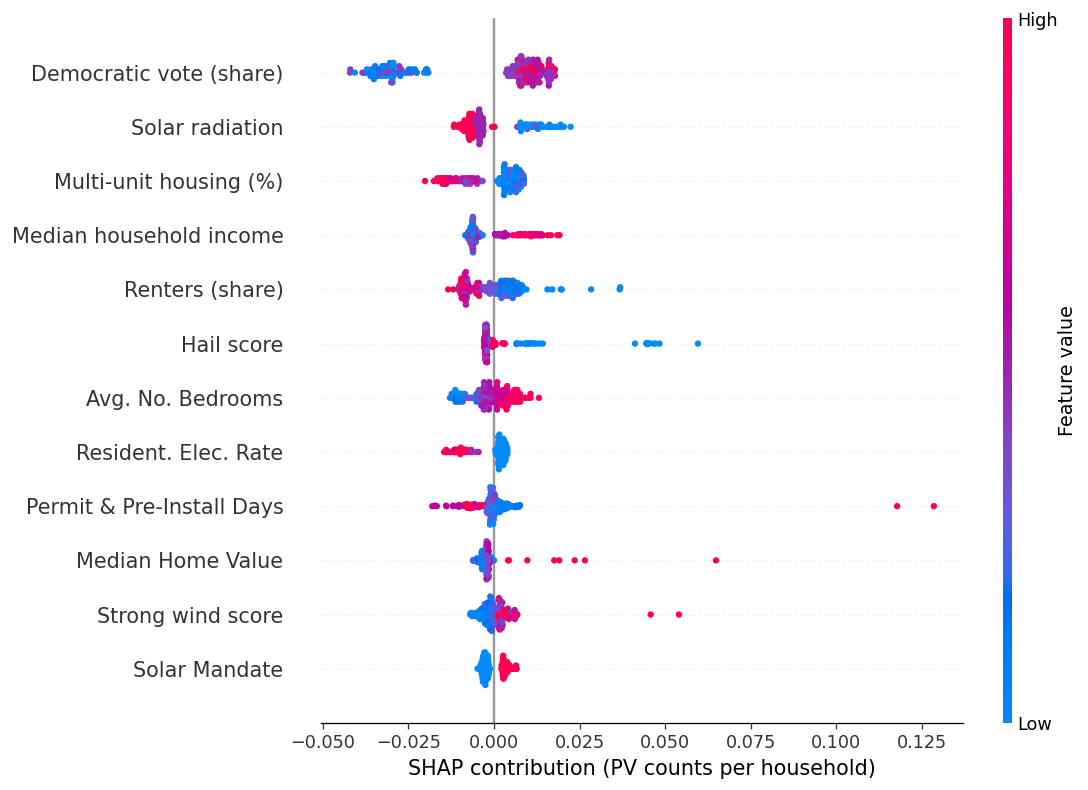

,feature,mean_absolute_SHAP
dem_votes,Democratic vote (share),0.01757
dniavg,Solar radiation,0.00755
EP_MUNIT,Multi-unit housing (%),0.00670
mh_income_2019,Median household income,0.00659
prop_renteroccupied,Renters (share),0.00596
HAIL_EALS,Hail score,0.00488
avg_bdrooms,Avg. No. Bedrooms,0.00451
res_rate,Resident. Elec. Rate,0.00428
permitandpreinstalldays,Permit & Pre-Install Days,0.00402
MedianHomeValue,Median Home Value,0.00331


In [26]:
shap.plots.beeswarm(  # Compare feature contributions across neighborhoods
    plot_values,  # Use the full explanation sample
    max_display=12,  # Show the 12 highest-ranked features
    group_remaining_features=False,  # Omit other features from this plot
    plot_size=(10, 7),  # Set the plot dimensions
    show=False,  # Allow formatting before display
)
plt.xlabel('SHAP contribution (PV counts per household)')  # Identify the contribution units
plt.tight_layout()  # Fit labels within the figure
plt.show()  # Display the beeswarm

global_shap = pd.DataFrame({  # Summarize attribution magnitude for each feature
    'feature': [FEATURE_LABELS[f] for f in FEATURES],  # Add readable feature labels
    'mean_absolute_SHAP': np.abs(shap_values.values).mean(axis=0),  # Average contribution magnitudes across neighborhoods
}, index=FEATURES).sort_values('mean_absolute_SHAP', ascending=False)  # Rank features from largest to smallest
display(global_shap.head(10).round(5))  # Show the ten highest-ranked features

#### 8b. Dependence scatter: how does income's contribution vary?

For each explained neighborhood, the horizontal axis is its median household income and the vertical axis is the contribution assigned to income. The colors show median home value, a potentially related feature. Vertical spread at similar income values can reflect interactions and other differences among neighborhoods; it does not identify a single causal mechanism.

This scatter is not a plot of predicted outcomes against income with all other features held fixed. It displays income's attribution for the different neighborhoods actually being explained.

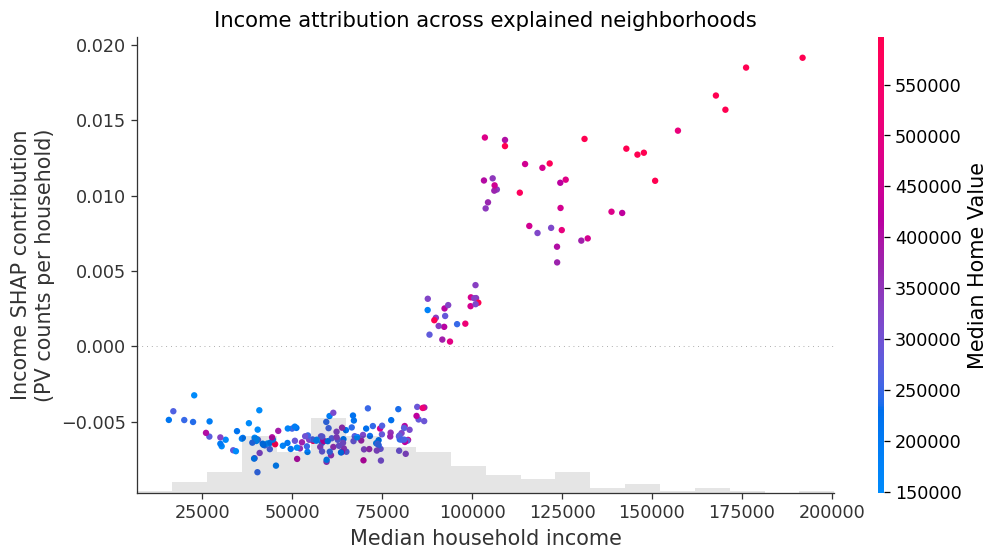

In [29]:
income_label = FEATURE_LABELS['mh_income_2019']  # Get the readable income label
home_value_label = FEATURE_LABELS['MedianHomeValue']  # Get the readable home-value label
shap.plots.scatter(  # Plot income values against income's contribution
    plot_values[:, income_label],  # Select income explanations for all sampled neighborhoods
    color=plot_values[:, home_value_label],  # Color the points by median home value
    show=False,  # Allow formatting before display
)
plt.gcf().set_size_inches(9, 5)  # Resize the current figure
plt.ylabel('Income SHAP contribution\n(PV counts per household)')  # Label income's contribution and units
plt.title('Income attribution across explained neighborhoods')  # Describe the comparison
plt.tight_layout()  # Fit labels within the figure
plt.show()  # Display the dependence scatter